# 01 - Data inventory and exploration
Goal: understand each raw dataset (columns, CRS, resolution, missing values) **before** building the grid.
Run the cells in order. If a cell fails, copy the error and the printed output back to Claude.
Each section is independent, so you can skip one and come back to it.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()          # notebook lives in notebooks/
RAW = ROOT / "data" / "raw"
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

# Bounding box that covers Algeria + Tunisia (lon_min, lat_min, lon_max, lat_max)
BBOX = (-9.0, 18.5, 12.5, 38.0)

pd.set_option("display.max_columns", 50)
print("Project root:", ROOT)

Project root: C:\Users\Lenovo\Desktop\S\M2\S3\DM\PROJET\forest-fire-dm


## 1. Fires (NASA FIRMS, VIIRS NOAA-20 = `viirs-jpss1`, 2024)

In [3]:
fire_dir = RAW / "fires" / "viirs-jpss1_2024_all_countries" / "viirs-jpss1" / "2024"
dz = pd.read_csv(fire_dir / "viirs-jpss1_2024_Algeria.csv");  dz["country"] = "Algeria"
tn = pd.read_csv(fire_dir / "viirs-jpss1_2024_Tunisia.csv");  tn["country"] = "Tunisia"
fires = pd.concat([dz, tn], ignore_index=True)

print("Shape:", fires.shape)
print(fires.dtypes)
fires.head()

Shape: (90250, 16)
latitude      float64
longitude     float64
bright_ti4    float64
scan          float64
track         float64
acq_date       object
acq_time        int64
satellite      object
instrument     object
confidence     object
version         int64
bright_ti5    float64
frp           float64
daynight       object
type            int64
country        object
dtype: object


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type,country
0,27.72818,9.87200,295.51,0.76,0.77,2024-01-01,3,N20,VIIRS,n,2,277.66,1.24,N,2,Algeria
1,28.63288,9.77909,301.80,0.79,0.78,2024-01-01,3,N20,VIIRS,n,2,277.05,1.57,N,2,Algeria
2,28.64012,9.77953,298.65,0.79,0.78,2024-01-01,3,N20,VIIRS,n,2,277.04,1.34,N,2,Algeria
3,36.74886,6.25409,338.04,0.46,0.39,2024-01-01,141,N20,VIIRS,n,2,257.28,5.21,N,2,Algeria
4,35.87978,4.44782,309.49,0.41,0.37,2024-01-01,141,N20,VIIRS,n,2,272.08,1.58,N,2,Algeria


In [4]:
print("Missing values:\n", fires.isna().sum())
print()
for col in ["confidence", "type", "daynight", "satellite", "instrument", "country"]:
    if col in fires.columns:
        print(fires[col].value_counts(dropna=False), "\n")
fires.describe().T

Missing values:
 latitude      0
longitude     0
bright_ti4    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_ti5    0
frp           0
daynight      0
type          0
country       0
dtype: int64

confidence
n    84128
l     5013
h     1109
Name: count, dtype: int64 

type
2    75495
0    14216
3      539
Name: count, dtype: int64 

daynight
N    68979
D    21271
Name: count, dtype: int64 

satellite
N20    90250
Name: count, dtype: int64 

instrument
VIIRS    90250
Name: count, dtype: int64 

country
Algeria    87446
Tunisia     2804
Name: count, dtype: int64 



,count,mean,std,min,25%,50%,75%,max
latitude,90250.0,31.476760,2.666477,19.60323,28.91151,31.409125,32.560313,37.32346
longitude,90250.0,6.280033,2.593748,-8.11805,5.64216,6.557880,8.083758,11.11035
bright_ti4,90250.0,321.091793,18.205551,240.17000,305.38000,316.710000,337.400000,367.00000
scan,90250.0,0.475991,0.101596,0.32000,0.40000,0.450000,0.540000,0.80000
track,90250.0,0.515446,0.126508,0.36000,0.39000,0.490000,0.620000,0.78000
acq_time,90250.0,380.331623,480.710563,0.00000,59.00000,140.000000,232.000000,1410.00000
version,90250.0,2.000000,0.000000,2.00000,2.00000,2.000000,2.000000,2.00000
bright_ti5,90250.0,291.726092,11.700269,244.79000,282.90000,290.790000,298.100000,355.42000
frp,90250.0,3.447776,5.222111,0.06000,1.15000,2.060000,3.920000,251.89000
type,90250.0,1.690936,0.735207,0.00000,2.00000,2.000000,2.000000,3.00000


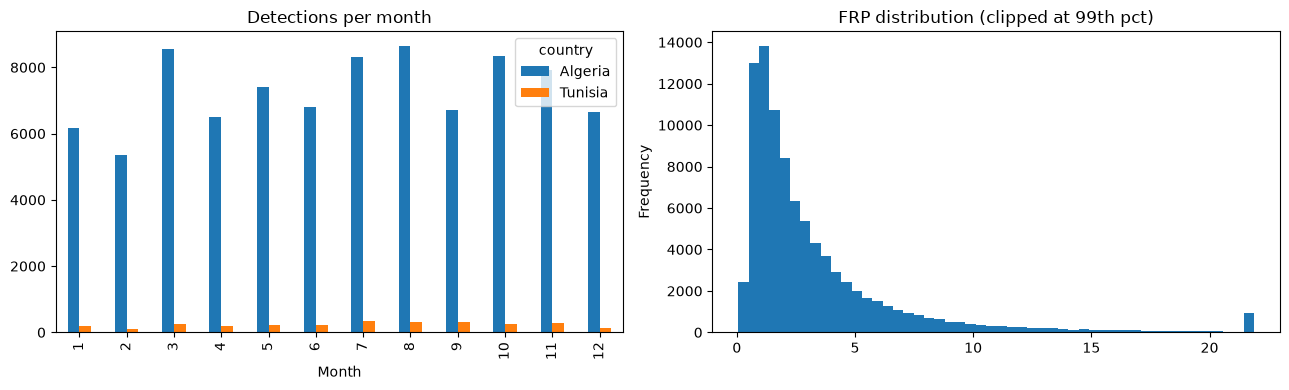

In [5]:
fires["acq_date"] = pd.to_datetime(fires["acq_date"])
fires["month"] = fires["acq_date"].dt.month

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
fires.groupby(["month", "country"]).size().unstack(fill_value=0).plot(kind="bar", ax=ax[0])
ax[0].set_title("Detections per month"); ax[0].set_xlabel("Month")
fires["frp"].clip(upper=fires["frp"].quantile(0.99)).plot(kind="hist", bins=50, ax=ax[1])
ax[1].set_title("FRP distribution (clipped at 99th pct)")
plt.tight_layout(); plt.savefig(FIG / "fires_monthly_frp.png", dpi=200); plt.show()

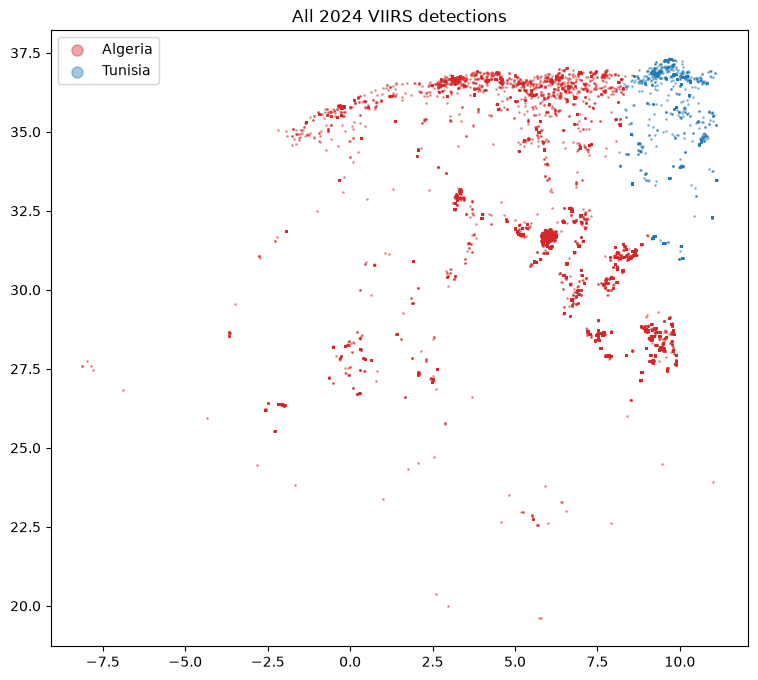

Fire lon range: -8.11805 11.11035
Fire lat range: 19.60323 37.32346


In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
colors = {"Algeria": "tab:red", "Tunisia": "tab:blue"}
for c, g in fires.groupby("country"):
    ax.scatter(g["longitude"], g["latitude"], s=1, alpha=0.4, c=colors[c], label=c)
ax.set_title("All 2024 VIIRS detections"); ax.legend(markerscale=8)
plt.savefig(FIG / "fires_map_all.png", dpi=200); plt.show()
print("Fire lon range:", fires.longitude.min(), fires.longitude.max())
print("Fire lat range:", fires.latitude.min(), fires.latitude.max())

**Look at the map above.** Many points deep in the Sahara are probably gas flares or industrial sources, not wildfires.
In Section 2 we will check which land cover those points fall on; this is how the project will filter them.

## 2. Land cover (FAO GlobCover shapefiles)

In [8]:
import geopandas as gpd

lc_dz = gpd.read_file(RAW / "landcover" / "geonetwork_landcover_DZA_gc_adg" / "dza_gc_adg.shp")
lc_tn = gpd.read_file(RAW / "landcover" / "geonetwork_landcover_tun_gc_adg" / "tun_gc_adg.shp")

for name, g in [("Algeria", lc_dz), ("Tunisia", lc_tn)]:
    print(name, "| rows:", len(g), "| CRS:", g.crs)
    print(g.dtypes, "\n")
lc_dz.head()

Algeria | rows: 386454 | CRS: EPSG:4326
ID             int32
GRIDCODE       int32
AREA         float64
LCCCODE       object
geometry    geometry
dtype: object 

Tunisia | rows: 52059 | CRS: EPSG:4326
AREA_M2      float64
ID             int32
GRIDCODE       int32
LCCCode       object
geometry    geometry
dtype: object 



,ID,GRIDCODE,AREA,LCCCODE,geometry
0,4,210,6.228187e+06,7001 // 8001,"POLYGON ((6.41528 37.08696, 6.43103 37.0855, 6..."
1,2,210,6.242408e+06,7001 // 8001,"POLYGON ((7.18084 37.07917, 7.17998 37.08091, ..."
2,1,210,1.482995e+06,7001 // 8001,"POLYGON ((7.37137 37.08194, 7.3709 37.08717, 7..."
3,8,50,4.590841e+08,21497-121340,"POLYGON ((6.12361 36.68472, 6.12361 36.69306, ..."
4,13,210,6.371533e+06,7001 // 8001,"POLYGON ((6.26181 37.02361, 6.26193 37.02514, ..."


The `.prj` files are empty (0 MB), so the CRS is probably missing. GlobCover is in WGS84; we set it manually if needed.

In [9]:
for g in (lc_dz, lc_tn):
    if g.crs is None:
        g.set_crs(epsg=4326, inplace=True)
print(lc_dz.crs, lc_tn.crs)
print("Algeria bounds:", lc_dz.total_bounds)
print("Tunisia bounds:", lc_tn.total_bounds)

EPSG:4326 EPSG:4326
Algeria bounds: [-8.67386723 18.96002769 11.97954845 37.09373474]
Tunisia bounds: [ 7.524827   30.24043083 11.59827042 37.54393005]


In [10]:
# Look at the legend files that ship with the data
for f in (RAW / "landcover" / "geonetwork_landcover_DZA_gc_adg").glob("*.xls"):
    print("=====", f.name)
    try:
        print(pd.read_excel(f).head(40).to_string())
    except Exception as e:
        print("Could not read (maybe install xlrd: pip install xlrd):", e)

===== globcover_LCCS_legend_africa.xls
Could not read (maybe install xlrd: pip install xlrd): Missing optional dependency 'xlrd'. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install xlrd.
===== globcover_legend.xls
Could not read (maybe install xlrd: pip install xlrd): Missing optional dependency 'xlrd'. Install xlrd >= 2.0.1 for xls Excel support Use pip or conda to install xlrd.


After seeing the columns above, set `LC_COL` to the column that holds the class code, then run the next cell.

In [12]:
LC_COL = None   # <- e.g. "GRIDCODE" or "VALUE" ; fill in after reading the columns above

if LC_COL:
    print(lc_dz[LC_COL].value_counts().head(25))
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    lc_dz.plot(column=LC_COL, ax=ax[0], cmap="tab20"); ax[0].set_title("Algeria")
    lc_tn.plot(column=LC_COL, ax=ax[1], cmap="tab20"); ax[1].set_title("Tunisia")
    plt.savefig(FIG / "landcover_maps.png", dpi=150); plt.show()

## 3. Climate (WorldClim CRU-TS 4.09, 5 min) - only 2024 is needed

In [16]:
import rasterio
from rasterio.windows import from_bounds

CLIM = RAW / "climate"
def clim_path(var, month, year=2024):
    return CLIM / f"wc2.1_cruts4.09_5m_{var}_2020-2024" / f"wc2.1_cruts4.09_5m_{var}_{year}-{month:02d}.tif"

for v in ["tmin", "tmax", "prec"]:
    p = clim_path(v, 1)
    print(v, "exists:", p.exists())

with rasterio.open(clim_path("tmax", 7)) as src:
    print("\nCRS:", src.crs, "| size:", src.width, "x", src.height, "| res:", src.res,
          "| nodata:", src.nodata, "| dtype:", src.dtypes[0], "| bands:", src.count)

tmin exists: True
tmax exists: True
prec exists: True

CRS: EPSG:4326 | size: 4320 x 2160 | res: (0.08333333333333333, 0.08333333333333333) | nodata: nan | dtype: float32 | bands: 1


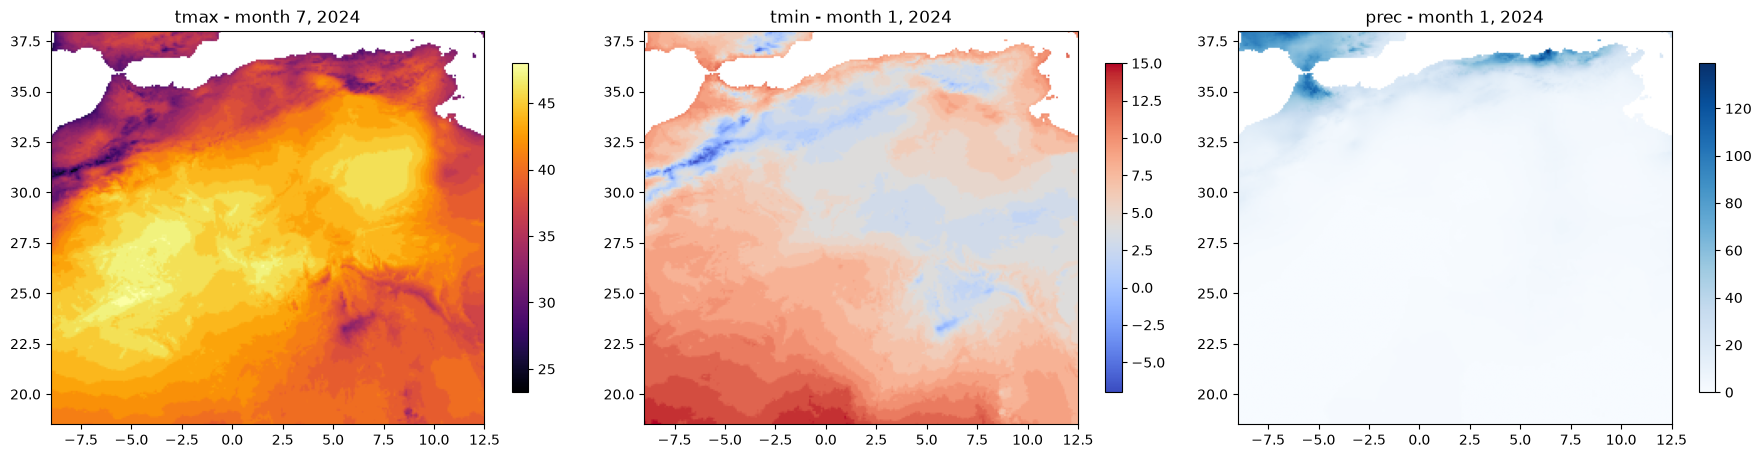

In [17]:
def read_crop(path, bbox=BBOX):
    with rasterio.open(path) as src:
        win = from_bounds(*bbox, transform=src.transform)
        arr = src.read(1, window=win, masked=True)
        extent = (bbox[0], bbox[2], bbox[1], bbox[3])
    return arr, extent

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (v, m, cm) in zip(ax, [("tmax", 7, "inferno"), ("tmin", 1, "coolwarm"), ("prec", 1, "Blues")]):
    arr, ext = read_crop(clim_path(v, m))
    im = a.imshow(arr, extent=ext, cmap=cm); a.set_title(f"{v} - month {m}, 2024")
    plt.colorbar(im, ax=a, shrink=0.7)
plt.tight_layout(); plt.savefig(FIG / "climate_examples.png", dpi=150); plt.show()

In [18]:
# Quick check: sample July tmax at the fire points
coords = list(zip(fires["longitude"], fires["latitude"]))
with rasterio.open(clim_path("tmax", 7)) as src:
    vals = np.array([v[0] for v in src.sample(coords)], dtype="float64")
    if src.nodata is not None:
        vals[vals == src.nodata] = np.nan
fires["tmax_jul_demo"] = vals
print("NaN at fire points:", np.isnan(vals).sum(), "of", len(vals))
fires["tmax_jul_demo"].describe()

NaN at fire points: 4 of 90250


count    90246.000000
mean        42.562743
std          4.267203
min         29.500000
25%         42.000000
50%         44.000000
75%         46.000000
max         47.000000
Name: tmax_jul_demo, dtype: float64

**Note for the report:** these files only give `tmin`, `tmax` and `prec`. Humidity and wind speed are not part of this download, so say so in the report.

## 4. Elevation (GMTED be15 - ArcInfo binary grid)

In [19]:
elev_path = RAW / "elevation" / "be15_grd"      # the folder is the dataset
with rasterio.open(elev_path) as src:
    print("Driver:", src.driver)
    print("CRS:", src.crs, "| size:", src.width, "x", src.height, "| res:", src.res)
    print("nodata:", src.nodata, "| dtype:", src.dtypes[0])
    print("Bounds:", src.bounds)

Driver: AIG
CRS: EPSG:4326 | size: 86400 x 33600 | res: (0.004166666666666664, 0.004166666666666664)
nodata: -32768.0 | dtype: int16
Bounds: BoundingBox(left=-180.00013888888893, bottom=-56.00013888888891, right=179.99986111111085, top=83.999861111111)


(468, 516) | min/max: -30 3939


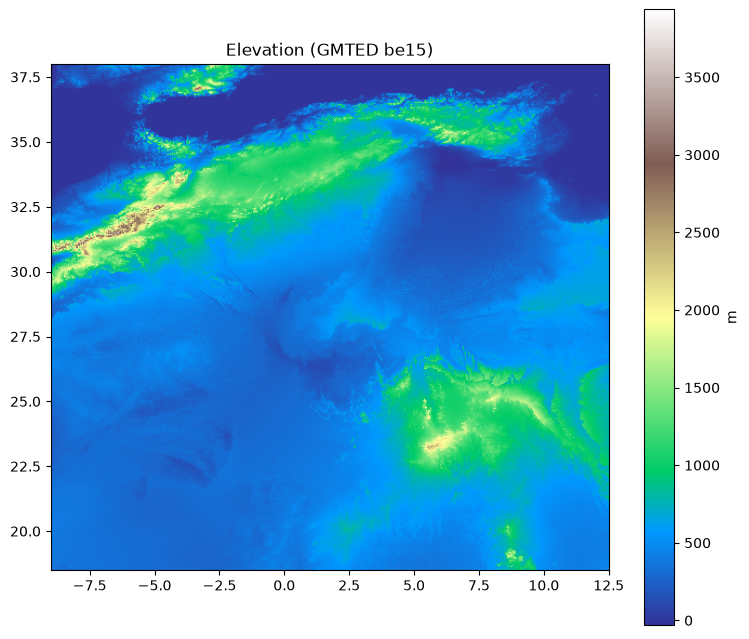

In [20]:
# Read only Algeria + Tunisia, downsampled 10x for plotting (the full grid is huge)
with rasterio.open(elev_path) as src:
    win = from_bounds(*BBOX, transform=src.transform)
    h, w = int(win.height), int(win.width)
    elev = src.read(1, window=win, out_shape=(h // 10, w // 10), masked=True)
print(elev.shape, "| min/max:", elev.min(), elev.max())

plt.figure(figsize=(9, 8))
plt.imshow(elev, extent=(BBOX[0], BBOX[2], BBOX[1], BBOX[3]), cmap="terrain")
plt.colorbar(label="m"); plt.title("Elevation (GMTED be15)")
plt.savefig(FIG / "elevation.png", dpi=150); plt.show()

## 5. Soil (HWSD v2)
What you have: `HWSD2_DB/HWSD2.mdb` (the attribute database).
What is missing: the **raster** (`HWSD2.bil` / `HWSD2_RASTER.zip`) from the same FAO page. Without it you cannot know which soil unit each location belongs to.
Also, `.mdb` files need the Microsoft Access ODBC driver on Windows. If the cell below fails,
).

In [24]:
soil_dir = RAW / "soil"
print("Files in soil folder:")
for p in sorted(soil_dir.rglob("*")):
    if p.is_file():
        print(" ", p.relative_to(soil_dir), f"{p.stat().st_size/1e6:.1f} MB")

raster_candidates = list(soil_dir.rglob("*.bil")) + list(soil_dir.rglob("*.tif"))
print("\nSoil raster found:", raster_candidates if raster_candidates else "NO - download HWSD2_RASTER.zip")

Files in soil folder:
  HWSD2_DB\HWSD2.mdb 91.6 MB
  HWSD2_DB.zip 9.3 MB
  HWSD2_RASTER\HWSD2.bil 1866.2 MB
  HWSD2_RASTER\HWSD2.hdr 0.0 MB
  HWSD2_RASTER\HWSD2.prj 0.0 MB
  HWSD2_RASTER\HWSD2.stx 0.0 MB
  HWSD2_RASTER.zip 22.4 MB

Soil raster found: [WindowsPath('C:/Users/Lenovo/Desktop/S/M2/S3/DM/PROJET/forest-fire-dm/data/raw/soil/HWSD2_RASTER/HWSD2.bil')]


In [26]:
# Option A: read the .mdb directly (needs "Microsoft Access Driver" + pip install pyodbc)
mdb = soil_dir / "HWSD2_DB" / "HWSD2.mdb"
try:
    import pyodbc
    print([d for d in pyodbc.drivers() if "Access" in d])
    conn = pyodbc.connect(rf"DRIVER={{Microsoft Access Driver (*.mdb, *.accdb)}};DBQ={mdb};")
    tables = [t.table_name for t in conn.cursor().tables(tableType="TABLE")]
    print(tables)
    layers = pd.read_sql("SELECT * FROM HWSD2_LAYERS WHERE LAYER = 'D1'", conn)
    layers.to_csv(soil_dir / "HWSD2_LAYERS_D1.csv", index=False)
    print(layers.shape)
except Exception as e:
    print("Option A failed:", e)
    print("Use Option B (export to CSV with mdbtools in WSL).")

['Microsoft Access Driver (*.mdb, *.accdb)', 'Microsoft Access Text Driver (*.txt, *.csv)']
['D_ADD_PROP', 'D_AWC', 'D_COVERAGE', 'D_DRAINAGE', 'D_FAO90', 'D_IL', 'D_KOPPEN', 'D_PHASE', 'D_ROOT_DEPTH', 'D_ROOTS', 'D_SWR', 'D_TEXTURE', 'D_TEXTURE_SOTER', 'D_TEXTURE_USDA', 'D_WRB_PHASES', 'D_WRB2', 'D_WRB2code', 'D_WRB4', 'HWSD2_LAYERS', 'HWSD2_LAYERS_METADATA', 'HWSD2_SMU', 'HWSD2_SMU_METADATA', 'WRB_Class', 'WRB_Layer', 'WRB_Library']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28712\1856252228.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  layers = pd.read_sql("SELECT * FROM HWSD2_LAYERS WHERE LAYER = 'D1'", conn)


(58405, 48)


In [23]:
# Option B: after exporting the CSVs, load them here
f = soil_dir / "HWSD2_LAYERS_D1.csv"
if f.exists():
    layers = pd.read_csv(f)
    wanted = ["COARSE","SAND","SILT","CLAY","TEXTURE_USDA","TEXTURE_SOTER","BULK","REF_BULK","ORG_CARBON",
              "PH_WATER","TOTAL_N","CN_RATIO","CEC_SOIL","CEC_CLAY","CEC_EFF","TEB","BSAT","ALUM_SAT","ESP",
              "TCARBON_EQ","GYPSUM","ELEC_COND"]
    print("Rows:", layers.shape, "| Missing required columns:", [c for c in wanted if c not in layers.columns])
    print(layers[[c for c in wanted if c in layers.columns]].describe().T)
else:
    print("HWSD2_LAYERS_D1.csv not found yet.")

HWSD2_LAYERS_D1.csv not found yet.


## Summary to fill in
| Dataset | Format | CRS | Resolution | Key issue |
|---|---|---|---|---|
| Fires | CSV | WGS84 | 375 m | filter `type`, low confidence, gas flares |
| Land cover | Shapefile | missing .prj -> set EPSG:4326 | polygons | find class column, group classes |
| Climate | GeoTIFF x12 per var | WGS84 | 5 arc-min (~9 km) | only tmin/tmax/prec |
| Elevation | ArcInfo grid | WGS84 | fine | read by window |
| Soil | .mdb + raster | - | - | raster missing, mdb needs driver |